In [ ]:
import scipy.ndimage as ndi
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
import math
import nibabel as nib
import skimage.transform
import pathlib
import pandas as pd
from scipy import ndimage
import skimage.feature, skimage.measure, skimage.morphology, skimage.segmentation
import glob
import keras
from keras.models import Sequential, Model
from keras.layers import Dense, Dropout, Activation, Flatten, BatchNormalization, \
    Conv2D, MaxPooling2D, ZeroPadding2D, Input, Embedding, \
    Lambda, UpSampling2D, Cropping2D, Conv2DTranspose, concatenate
import tensorflow as tf
from keras.optimizers import SGD, Adam
from keras.callbacks import ModelCheckpoint, LearningRateScheduler, ReduceLROnPlateau, CSVLogger
from keras import backend as K
from keras import optimizers
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import array_to_img
from skimage.transform import resize
from tensorflow.keras import models, layers, regularizers
from tensorflow.keras import backend as K
from tensorflow.keras.utils import array_to_img, Sequence


In [ ]:
#### Load train data of 3d mask with npy
#################################################

path = "/kaggle/input/newnodules/new_ct (S123)/"
mask_path = "/kaggle/input/newnodules/new_mask (S123)/"

CT_list = glob.glob(path + "*.npy")
mask_list = glob.glob(mask_path + "*.npy")

Patient_ID = []
x_train = []
y_train = []



for i in range(len(CT_list)):
  Patient_ID.append(CT_list[i].split("/")[-1][:-4])
  print(i)

  temp = np.load(CT_list[i])
  mask_temp = np.load(mask_path + Patient_ID[i] + ".npy")

  x = np.zeros((np.shape(temp)[0], 256, 256))
  y = np.zeros((np.shape(temp)[0], 256, 256))

  for j in range(np.shape(temp)[0]):



    x[j, :, :] = (resize(temp[j, :, :], (256, 256)))
    y[j, :, :] = (resize(mask_temp[j, :, :], (256, 256)))



  x_train.append(x)
  y_train.append(y)



x_train = np.concatenate(x_train, axis=0)
y_train = np.concatenate(y_train, axis=0)

# Y_train = np.multiply(Y_train,1)
del temp, mask_temp, x, y

In [15]:
#### Shuffle data

indices = np.arange(x_train.shape[0])
np.random.shuffle(indices)

x_train = x_train[indices, :, :]
y_train = y_train[indices, :, :]

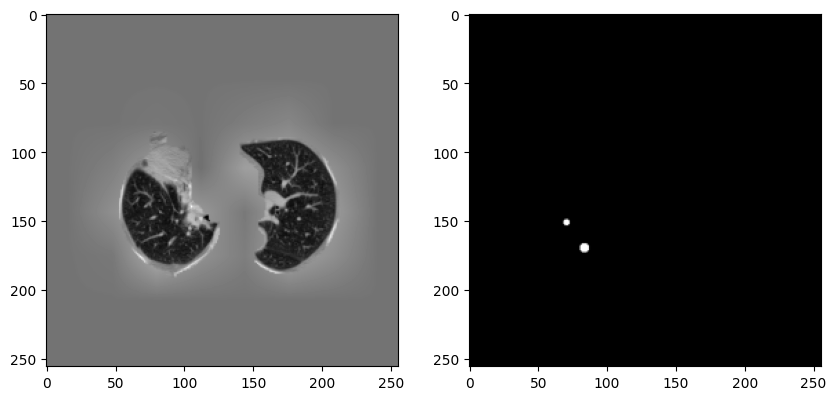

In [16]:
index = 950
plt.figure(figsize=[10, 10])
plt.subplot(121)
plt.imshow(x_train[index, :, :], cmap="gray")
plt.subplot(122)
plt.imshow(y_train[index, :, :], cmap="gray")
plt.show()

In [ ]:
###### Normalize
epsilon = np.finfo(x_train.dtype).eps
for i in range(len(x_train)):
  temp = x_train[i, :, :]

  x_train[i, :, :] = (temp - np.min(temp))/ (np.max(temp)-np.min(temp)+epsilon)



In [18]:
np.min(x_train)

0.0

In [ ]:

def dice_coef(y_true, y_pred):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + 1) / (K.sum(y_true_f) + K.sum(y_pred_f) + 1)

def dice_coef_loss(y_true, y_pred):
    return 1-dice_coef(y_true, y_pred)



# Dice Coefficient Metric
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

# Sensitivity (Recall) Metric
def sensitivity_metric(y_true, y_pred):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    true_positives = K.sum(y_true_f * y_pred_f)
    possible_positives = K.sum(y_true_f)
    return true_positives / (possible_positives + K.epsilon())

# Precision Metric
def precision_metric(y_true, y_pred):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    true_positives = K.sum(y_true_f * y_pred_f)
    predicted_positives = K.sum(y_pred_f)
    return true_positives / (predicted_positives + K.epsilon())


def dice_coef_loss(y_true, y_pred, smooth=1e-6):
    # Flatten the predictions and labels
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    
    # Calculate the Dice coefficient
    intersection = K.sum(y_true_f * y_pred_f)
    dice = (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)
    
    return dice


def f1_score(y_true, y_pred):
 
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    TP = tf.keras.backend.sum(y_true_f * y_pred_f)
    FP = tf.keras.backend.sum(y_pred_f * (1 - y_true_f))
    FN = tf.keras.backend.sum((1 - y_pred_f) * y_true_f)
    precision = TP / (TP + FP + tf.keras.backend.epsilon())
    recall = TP / (TP + FN + tf.keras.backend.epsilon())
    f1 = 2 * (precision * recall) / (precision + recall + tf.keras.backend.epsilon())
    
    return f1

In [20]:
X_train , X_test, Y_train, Y_test = train_test_split(x_train, y_train, test_size=0.05, random_state=32)
del x_train, y_train

In [21]:
X_train = np.reshape(X_train, (len(X_train), 256, 256, 1))
Y_train = np.reshape(Y_train, (len(Y_train), 256, 256, 1))
X_test = np.reshape(X_test, (len(X_test), 256, 256, 1))
Y_test = np.reshape(Y_test, (len(Y_test), 256, 256, 1))

In [ ]:

#convolutional block
def conv_block(x, kernelsize, filters, dropout, batchnorm=False):
    conv = layers.Conv2D(filters, (kernelsize, kernelsize), kernel_initializer='he_normal', padding="same")(x)
    if batchnorm is True:
        conv = layers.BatchNormalization(axis=3)(conv)
    conv = layers.Activation("relu")(conv)
    if dropout > 0:
        conv = layers.Dropout(dropout)(conv)
    conv = layers.Conv2D(filters, (kernelsize, kernelsize), kernel_initializer='he_normal', padding="same")(conv)
    if batchnorm is True:
        conv = layers.BatchNormalization(axis=3)(conv)
    conv = layers.Activation("relu")(conv)
    return conv


#residual convolutional block
def res_conv_block(x, kernelsize, filters, dropout, batchnorm=False):
    conv1 = layers.Conv2D(filters, (kernelsize, kernelsize), kernel_initializer='he_normal', padding='same')(x)
    if batchnorm is True:
        conv1 = layers.BatchNormalization(axis=3)(conv1)
    conv1 = layers.Activation('relu')(conv1)
    conv2 = layers.Conv2D(filters, (kernelsize, kernelsize), kernel_initializer='he_normal', padding='same')(conv1)
    if batchnorm is True:
        conv2 = layers.BatchNormalization(axis=3)(conv2)
        conv2 = layers.Activation("relu")(conv2)
    if dropout > 0:
        conv2 = layers.Dropout(dropout)(conv2)

    #skip connection
    shortcut = layers.Conv2D(filters, kernel_size=(1, 1), kernel_initializer='he_normal', padding='same')(x)
    if batchnorm is True:
        shortcut = layers.BatchNormalization(axis=3)(shortcut)
    shortcut = layers.Activation("relu")(shortcut)
    respath = layers.add([shortcut, conv2])
    return respath

batchnorm=True

filters = [32, 64, 128, 256, 512]
kernelsize = 3
upsample_size = 2
dropout=0.2

inputs = keras.Input(shape = (256, 256, 1))

# Downsampling layers
dn_conv1 = conv_block(inputs, kernelsize, filters[0], dropout, batchnorm)
dn_pool1 = layers.MaxPooling2D(pool_size=(2,2))(dn_conv1)

dn_conv2 = res_conv_block(dn_pool1, kernelsize, filters[1], dropout, batchnorm)
dn_pool2 = layers.MaxPooling2D(pool_size=(2,2))(dn_conv2)

dn_conv3 = res_conv_block(dn_pool2, kernelsize, filters[2], dropout, batchnorm)
dn_pool3 = layers.MaxPooling2D(pool_size=(2,2))(dn_conv3)

dn_conv4 = res_conv_block(dn_pool3, kernelsize, filters[3], dropout, batchnorm)
dn_pool4 = layers.MaxPooling2D(pool_size=(2,2))(dn_conv4)

dn_conv5 = res_conv_block(dn_pool4, kernelsize, filters[4], dropout, batchnorm)

# upsampling layers
up_conv6 = layers.UpSampling2D(size=(upsample_size, upsample_size), data_format="channels_last")(dn_conv5)
up_conv6 = layers.concatenate([up_conv6, dn_conv4], axis=3)
up_conv6 = res_conv_block(up_conv6, kernelsize, filters[3], dropout, batchnorm)

up_conv7 = layers.UpSampling2D(size=(upsample_size, upsample_size), data_format="channels_last")(up_conv6)
up_conv7 = layers.concatenate([up_conv7, dn_conv3], axis=3)
up_conv7 = res_conv_block(up_conv7, kernelsize, filters[2], dropout, batchnorm)

up_conv8 = layers.UpSampling2D(size=(upsample_size, upsample_size), data_format="channels_last")(up_conv7)
up_conv8 = layers.concatenate([up_conv8, dn_conv2], axis=3)
up_conv8 = res_conv_block(up_conv8, kernelsize, filters[1], dropout, batchnorm)

up_conv9 = layers.UpSampling2D(size=(upsample_size, upsample_size), data_format="channels_last")(up_conv8)
up_conv9 = layers.concatenate([up_conv9, dn_conv1], axis=3)
up_conv9 = res_conv_block(up_conv9, kernelsize, filters[0], dropout, batchnorm)


conv_final = layers.Conv2D(1, kernel_size=(1,1))(up_conv9)
conv_final = layers.BatchNormalization(axis=3)(conv_final)
outputs = layers.Activation('sigmoid')(conv_final)

model = models.Model(inputs=[inputs], outputs=[outputs])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256, 256,  │          0 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ dropout[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 128, 128,  │      2,112 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 128, 128,  │          0 │ batch_normalizat

 Total params: 8,300,261 (31.66 MB)

 Trainable params: 8,291,491 (31.63 MB)

 Non-trainable params: 8,770 (34.26 KB)

In [31]:
from keras.callbacks import ModelCheckpoint

filepath = "resU-net with DSC+sen Loss.h5.keras"

checkpoint = ModelCheckpoint(filepath, monitor='val_dice_coef', verbose=1, save_best_only=True, mode='max')

In [ ]:
from sklearn.utils import shuffle
opt = optimizers.Adam(learning_rate = 0.005)

model.compile(optimizer = opt, loss=dice_coef_loss, 
              metrics= [dice_coef, sensitivity_metric, precision_metric, f1_score])

In [ ]:

history = model.fit(X_train, Y_train,
                    batch_size=16,
                    shuffle = True,
                    epochs=100,
                    validation_split=0.1,
                    verbose=1,
                    callbacks=[checkpoint])

In [36]:
pred = model.predict(X_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 364ms/step


In [37]:
pred = np.squeeze(pred, axis=-1)

In [38]:
score = model.evaluate(X_test, Y_test, verbose = 0)

print('Test loss:', score[0])
print('Test DICE:', score[1])
print('Test Sen:', score[2])
print('Test Pre:', score[3])
print('Test F1:', score[4])

Test loss: 0.18622106313705444
Test DICE: 0.8343076705932617
Test Sen: 0.7357454299926758
Test Pre: 0.783072829246521
Test F1: 0.7575981616973877


In [ ]:
# model.save_weights('/content/drive/MyDrive/Luna-16/Results Nodule seg/residual/WeightresUnet-200epoch-Lr0.005-1350 data-diceloss-bs16-re-tr86va86te69.h5')